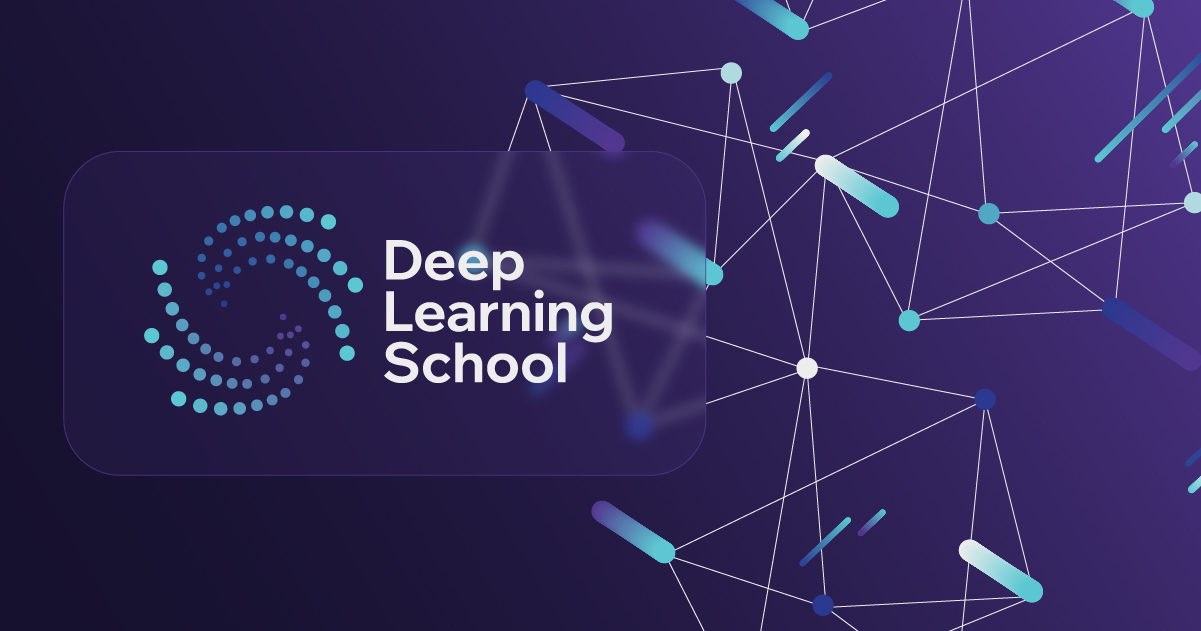

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание по теме "Механизм внимания.</b></h1>


Это домашнее задание проходит в формате peer-review. Это означает, что его будут проверять ваши однокурсники. Поэтому пишите разборчивый код, добавляйте комментарии и пишите выводы после проделанной работы.

В этом задании вы будете решать задачу классификации математических задач по темам (многоклассовая классификация) с помощью Transformer.

В качестве датасета возьмем датасет математических задач по разным темам. Нам необходим следующий файл:

[Файл с классами](https://docs.google.com/spreadsheets/d/13YIbphbWc62sfa-bCh8MLQWKizaXbQK9/edit?usp=drive_link&ouid=104379615679964018037&rtpof=true&sd=true)

**Hint:** не перезаписывайте модели, которые вы получите на каждом из этапов этого дз. Они ещё понадобятся.

In [2]:
import os
from kaggle_secrets import UserSecretsClient

client = UserSecretsClient()
os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

### Работа с данными

In [3]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, f1_score

In [4]:
data_path = "/kaggle/input/datasets/egrsid/data-problems-translated/data_problems_translated.xlsx"
df = pd.read_excel(data_path).drop('Unnamed: 0', axis=1).dropna()
df.sample(5)

,problem_text,topic
3825,The castle is surrounded by a circular wall wi...,dirichlet
1498,(b) Passengers may be driving in such a way th...,dirichlet
5048,Let P(x) be a multi-member of the degree n > 1...,polynoms
1202,"Find the residuals of the number 22001 by 3, 5...",number_theory
4166,In the connected graph of the degrees of all t...,combinatorics


In [5]:
df.shape

(5268, 2)

In [6]:
df['topic'].unique()

array(['number_theory', 'polynoms', 'combinatorics', 'graphs', 'geometry',
       'invariant', 'dirichlet'], dtype=object)

In [7]:
texts_lens = df['problem_text'].apply(lambda x: len(str(x)))
texts_lens.mean(), texts_lens.max(), texts_lens.min()

(np.float64(230.1497722095672), 2506, 3)

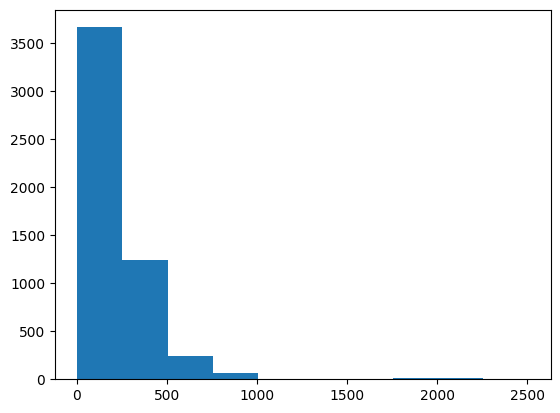

In [8]:
plt.hist(texts_lens);

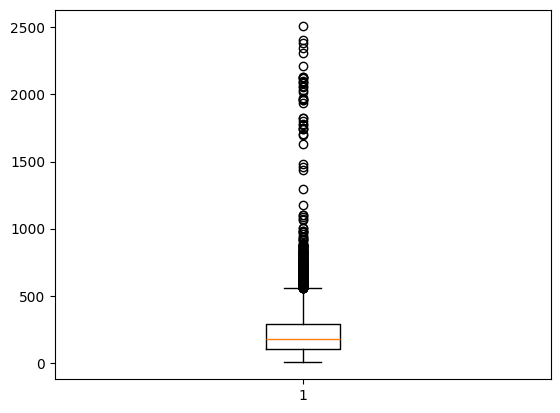

In [9]:
plt.boxplot(texts_lens);

значит от 500 будут выбросы -> поставлю максимальную длину 600 при обучении rubert, максимальную доступную длину (512) для mathbert

In [10]:
le = LabelEncoder()
df['topic_le'] = le.fit_transform(df['topic'])
df

,problem_text,topic,topic_le
0,To prove that the sum of the numbers of the ex...,number_theory,5
1,( b) Will the statement of the previous challe...,number_theory,5
2,The quadratic three-member graph with the coef...,polynoms,6
3,Can you draw on the surface of Rubik's cube a ...,combinatorics,0
4,"Dima, who came from Vrunlandia, said that ther...",graphs,3
...,...,...,...
5268,Can the number n! end with the figures of 76.0...,number_theory,5
5269,Find all natural m and n for which m! + 12 = n2.,number_theory,5
5270,"The correct 5,000-column has a 2001 vertebrate...",dirichlet,1
5271,Find the maximum number N for which there are ...,number_theory,5


In [11]:
def preprocess_func(examples, tokenizer, mx_len):
    model_inputs = tokenizer(examples['problem_text'], max_length=mx_len, truncation=True)
    model_inputs['labels'] = examples['topic_le']

    return model_inputs

In [65]:
def make_pandas_dataset(train_frac=0.8, test_frac=0.5):
    train_df = df.sample(frac=train_frac, random_state=42)
    test_df = df.drop(train_df.index)
    val_df = test_df.sample(frac=test_frac, random_state=42)
    test_df = test_df.drop(val_df.index)

    return train_df, val_df, test_df

In [67]:
train_df, val_df, test_df = make_pandas_dataset(train_frac=0.8, test_frac=0.5)

In [68]:
def make_dataset(df, tokenizer, mx_len):
    train_dataset = Dataset.from_pandas(train_df, 
                                    preserve_index=False).map(preprocess_func, batched=True, 
                                                              remove_columns=train_df.columns.tolist(),
                                                              fn_kwargs={'tokenizer': tokenizer, 'mx_len': mx_len})
    test_dataset = Dataset.from_pandas(test_df, 
                                    preserve_index=False).map(preprocess_func, batched=True, 
                                                              remove_columns=train_df.columns.tolist(),
                                                              fn_kwargs={'tokenizer': tokenizer, 'mx_len': mx_len})
    eval_dataset = Dataset.from_pandas(val_df, 
                                    preserve_index=False).map(preprocess_func, batched=True, 
                                                              remove_columns=train_df.columns.tolist(),
                                                              fn_kwargs={'tokenizer': tokenizer, 'mx_len': mx_len})

    return train_dataset, test_dataset, eval_dataset

In [13]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    res = {}
    res['accuracy'] = accuracy_score(labels, logits.argmax(axis=1))
    res['f1'] = f1_score(labels, logits.argmax(axis=1), average='macro')

    return res

### Задание 1 (2 балла)

Напишите кастомный класс для модели трансформера для задачи классификации, использующей в качествке backbone какую-то из моделей huggingface.

Т.е. конструктор класса должен принимать на вход название модели и подгружать её из huggingface, а затем использовать в качестве backbone (достаточно возможности использовать в качестве backbone те модели, которые упомянуты в последующих пунктах)

In [14]:
from transformers import AutoTokenizer, AutoModel, pipeline
import torch
import torch.nn as nn
import torch.nn.functional as F

In [15]:
### This is just an interface example. You may change it if you want.

class TransformerClassificationModel(nn.Module):
    def __init__(self, base_transformer_model, out_size, p=0.1):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(base_transformer_model, attn_implementation="eager")
        # YOUR CODE: create additional layers for classfication
        self.dropout = nn.Dropout(p)
        self.linear = nn.Linear(self.backbone.config.hidden_size, out_size)

    def forward(self, input_ids, attention_mask, labels=None, **kwargs):
        # YOUR CODE: propagate inputs through the model. Return dict with logits
        out = self.backbone(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0, :]
        out = self.linear(self.dropout(out))
        res = {'logits': out}

        if labels is not None:
            loss = F.cross_entropy(out, labels)
            res['loss'] = loss
            
        return res

### Задание 2 (1 балл)

Напишите функцию заморозки backbone у модели (если необходимо, возвращайте из функции модель)

In [15]:
def freeze_backbone_function(model: TransformerClassificationModel):
    model.backbone.requires_grad_(False)

### Задание 3 (2 балла)

Напишите функцию, которая будет использована для тренировки (дообучения) трансформера (TransformerClassificationModel). Функция должна поддерживать обучение с замороженным и размороженным backbone.

In [16]:
from transformers import Trainer, TrainingArguments

In [17]:
import copy

def train_transformer(transformer_model, train_dataset, eval_dataset, 
                      tokenizer, data_collator, freeze_backbone=True, epochs=3, lr=1e-4):
    model = copy.deepcopy(transformer_model)
    if freeze_backbone: freeze_backbone_function(model)

    training_args = TrainingArguments(
        output_dir="./out",
        num_train_epochs=epochs,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=16,
        eval_strategy='epoch',
        learning_rate=lr,
        weight_decay=1e-3,
        label_names=["labels"],
        report_to="none",
        save_strategy="no",
        logging_strategy="epoch"
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        processing_class=tokenizer,
        data_collator=data_collator,
        compute_metrics=compute_metrics
    )

    trainer.train()

    return model

### Задание 4 (1 балл)

Проверьте вашу функцию из предыдущего пункта, дообучив двумя способами
*cointegrated/rubert-tiny2* из huggingface.

In [18]:
from datasets import Dataset
from transformers import DataCollatorWithPadding

In [19]:
rubert_tiny_transformer_tokenizer = AutoTokenizer.from_pretrained('cointegrated/rubert-tiny2')
rubert_tiny_transformer_collator = DataCollatorWithPadding(tokenizer=rubert_tiny_transformer_tokenizer)

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

In [20]:
train_dataset, test_dataset, eval_dataset = make_dataset(
    df=df,
    tokenizer=rubert_tiny_transformer_tokenizer,
    mx_len=600
)

Map:   0%|          | 0/4214 [00:00<?, ? examples/s]

Map:   0%|          | 0/527 [00:00<?, ? examples/s]

Map:   0%|          | 0/527 [00:00<?, ? examples/s]

In [100]:
rubert_tiny_transformer_model = TransformerClassificationModel("cointegrated/rubert-tiny2", out_size=df['topic'].nunique())
rubert_tiny_finetuned_with_freezed_backbone = train_transformer(
    transformer_model=rubert_tiny_transformer_model,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    tokenizer=rubert_tiny_transformer_tokenizer,
    data_collator=rubert_tiny_transformer_collator,
    freeze_backbone=True,
    epochs=10,
    lr=1e-3,
)

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type:

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,2.822258,2.337250,0.578748,0.321293
2,2.388834,2.173190,0.603416,0.423664
3,2.265130,2.096393,0.603416,0.403008
4,2.192770,2.070232,0.607211,0.445924
5,2.151713,2.046076,0.607211,0.421410
6,2.128935,2.033315,0.612903,0.443889
7,2.113115,2.021990,0.611006,0.428027
8,2.095588,2.017004,0.616698,0.445489
9,2.097007,2.016219,0.614801,0.446678
10,2.071607,2.013637,0.618596,0.447557


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

In [108]:
rubert_tiny_transformer_model = TransformerClassificationModel("cointegrated/rubert-tiny2", out_size=df['topic'].nunique())
rubert_tiny_full_finetuned = train_transformer(
    transformer_model=rubert_tiny_transformer_model,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    tokenizer=rubert_tiny_transformer_tokenizer,
    data_collator=rubert_tiny_transformer_collator,
    freeze_backbone=False,
    epochs=10,
    lr=5e-5,
)

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type:

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,2.906032,2.367539,0.552182,0.299258
2,2.299536,2.050453,0.620493,0.446135
3,2.071527,1.950808,0.633776,0.468608
4,1.902936,1.940944,0.616698,0.473707
5,1.804304,1.892851,0.622391,0.468842
6,1.694936,1.909294,0.609108,0.468558
7,1.625344,1.904083,0.624288,0.487644
8,1.539247,1.942747,0.609108,0.494590
9,1.496910,1.934645,0.599620,0.485866
10,1.464177,1.930251,0.614801,0.500324


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

### Задание 5 (1 балл)

Обучите *tbs17/MathBert* (с замороженным backbone и без заморозки), проанализируйте результаты. Сравните скоры с первым заданием. Получилось лучше или нет? Почему?

In [21]:
mathbert_model_tokenizer = AutoTokenizer.from_pretrained('tbs17/MathBert')
mathbert_model_collator = DataCollatorWithPadding(tokenizer=mathbert_model_tokenizer)

config.json:   0%|          | 0.00/569 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

In [22]:
train_dataset, test_dataset, eval_dataset = make_dataset(
    df=df,
    tokenizer=mathbert_model_tokenizer,
    mx_len=512 # максимальная длина для этого токенизатора
)

Map:   0%|          | 0/4214 [00:00<?, ? examples/s]

Map:   0%|          | 0/527 [00:00<?, ? examples/s]

Map:   0%|          | 0/527 [00:00<?, ? examples/s]

In [115]:
mathbert_model = TransformerClassificationModel("tbs17/MathBert", out_size=df['topic'].nunique())
mathbert_model_with_freezed_backbone = train_transformer(
    transformer_model=mathbert_model,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    tokenizer=mathbert_model_tokenizer,
    data_collator=mathbert_model_collator,
    freeze_backbone=True,
    epochs=10,
    lr=1e-3,
)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  441MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input t

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,2.737954,2.237861,0.578748,0.329707
2,2.313038,2.096828,0.603416,0.429086
3,2.208123,2.077540,0.607211,0.418572
4,2.154804,2.078872,0.588235,0.418698
5,2.108931,2.067757,0.597723,0.407072
6,2.095736,2.072312,0.593928,0.425178
7,2.059903,2.069901,0.592030,0.418525
8,2.049348,2.082749,0.595825,0.417335
9,2.007340,2.061356,0.590133,0.426861
10,2.018944,2.063155,0.597723,0.425203


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector

In [124]:
mathbert_model = TransformerClassificationModel("tbs17/MathBert", out_size=df['topic'].nunique())
mathbert_model_full_finetuned = train_transformer(
    transformer_model=mathbert_model,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    tokenizer=mathbert_model_tokenizer,
    data_collator=mathbert_model_collator,
    freeze_backbone=False,
    epochs=3,
    lr=5e-5,
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input t

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,2.373279,2.247021,0.588235,0.340823
2,1.621154,1.978179,0.584440,0.480584
3,1.129184,2.136951,0.578748,0.491252


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


#### сохраним все полученные модели, чтобы иметь доступ между сессиями

In [118]:
torch.save(rubert_tiny_finetuned_with_freezed_backbone.state_dict(), "/kaggle/working/rubert_frozen.pt")
torch.save(rubert_tiny_full_finetuned.state_dict(), "/kaggle/working/rubert_full.pt")
torch.save(mathbert_model_with_freezed_backbone.state_dict(), "/kaggle/working/mathbert_frozen.pt")

In [125]:
torch.save(mathbert_model_full_finetuned.state_dict(), "/kaggle/working/mathbert_full.pt")

In [122]:
from huggingface_hub import HfApi

api = HfApi()
api.create_repo("egrsid/dls-attention-hw", private=True, exist_ok=True)

api.upload_file(path_or_fileobj="/kaggle/working/rubert_frozen.pt",
               path_in_repo="rubert_frozen.pt",
               repo_id="egrsid/dls-attention-hw")
api.upload_file(path_or_fileobj="/kaggle/working/rubert_full.pt",
               path_in_repo="rubert_full.pt",
               repo_id="egrsid/dls-attention-hw")
api.upload_file(path_or_fileobj="/kaggle/working/mathbert_frozen.pt",
               path_in_repo="mathbert_frozen.pt",
               repo_id="egrsid/dls-attention-hw")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

CommitInfo(commit_url='https://huggingface.co/egrsid/dls-attention-hw/commit/c627b78100c3eb1bca5f6977f16adfa5c7f08315', commit_message='Upload mathbert_frozen.pt with huggingface_hub', commit_description='', oid='c627b78100c3eb1bca5f6977f16adfa5c7f08315', pr_url=None, repo_url=RepoUrl('https://huggingface.co/egrsid/dls-attention-hw', endpoint='https://huggingface.co', repo_type='model', repo_id='egrsid/dls-attention-hw'), pr_revision=None, pr_num=None)

In [126]:
api.upload_file(path_or_fileobj="/kaggle/working/mathbert_full.pt",
               path_in_repo="mathbert_full.pt",
               repo_id="egrsid/dls-attention-hw")

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

CommitInfo(commit_url='https://huggingface.co/egrsid/dls-attention-hw/commit/bcc0ba578ffdb41a6d5016a51475a6ec5866bc90', commit_message='Upload mathbert_full.pt with huggingface_hub', commit_description='', oid='bcc0ba578ffdb41a6d5016a51475a6ec5866bc90', pr_url=None, repo_url=RepoUrl('https://huggingface.co/egrsid/dls-attention-hw', endpoint='https://huggingface.co', repo_type='model', repo_id='egrsid/dls-attention-hw'), pr_revision=None, pr_num=None)

#### теперь скачаем загруженные модели

In [23]:
rubert_tokenizer = AutoTokenizer.from_pretrained('cointegrated/rubert-tiny2')
rubert_collator = DataCollatorWithPadding(tokenizer=rubert_tokenizer)

In [24]:
mathbert_tokenizer = AutoTokenizer.from_pretrained('tbs17/MathBert')
mathbert_collator = DataCollatorWithPadding(tokenizer=mathbert_tokenizer)

In [25]:
from huggingface_hub import hf_hub_download

In [26]:
path_rubert_frozen = hf_hub_download(
    repo_id="egrsid/dls-attention-hw",
    filename="rubert_frozen.pt"
)

rubert_frozen = TransformerClassificationModel("cointegrated/rubert-tiny2", out_size=df['topic'].nunique())
rubert_frozen.load_state_dict(torch.load(path_rubert_frozen, map_location='cpu'))

rubert_frozen.pt: reconstructing file:   0%|          |  0.00B /  117MB            

rubert_frozen.pt: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<All keys matched successfully>

In [27]:
path_rubert_full = hf_hub_download(
    repo_id="egrsid/dls-attention-hw",
    filename="rubert_full.pt"
)

rubert_full = TransformerClassificationModel("cointegrated/rubert-tiny2", out_size=df['topic'].nunique())
rubert_full.load_state_dict(torch.load(path_rubert_full, map_location='cpu'))

rubert_full.pt: reconstructing file:   0%|          |  0.00B /  117MB            

rubert_full.pt: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<All keys matched successfully>

In [28]:
path_mathbert_frozen = hf_hub_download(
    repo_id="egrsid/dls-attention-hw",
    filename="mathbert_frozen.pt"
)

mathbert_frozen = TransformerClassificationModel("tbs17/MathBert", out_size=df['topic'].nunique())
mathbert_frozen.load_state_dict(torch.load(path_mathbert_frozen, map_location='cpu'))

mathbert_frozen.pt: reconstructing file:   0%|          |  0.00B /  438MB            

mathbert_frozen.pt: downloading bytes:           |  0.00B            

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  441MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<All keys matched successfully>

In [29]:
path_mathbert_full = hf_hub_download(
    repo_id="egrsid/dls-attention-hw",
    filename="mathbert_full.pt"
)

mathbert_full = TransformerClassificationModel("tbs17/MathBert", out_size=df['topic'].nunique())
mathbert_full.load_state_dict(torch.load(path_mathbert_full, map_location='cpu'))

mathbert_full.pt: reconstructing file:   0%|          |  0.00B /  438MB            

mathbert_full.pt: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: tbs17/MathBert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


<All keys matched successfully>

### Задание 6 (1 балл)

Напишите функцию для отрисовки карт внимания первого слоя для моделей из задания

In [146]:
@torch.no_grad()
def draw_first_layer_attention_maps(attention_head_ids, texts, model, tokenizer, max_tokens=30, layer=0):
    model.eval()

    n_rows, n_cols = len(attention_head_ids), len(texts)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.5 * n_cols, 4.5 * n_rows), squeeze=False)

    for c, text in enumerate(texts):
        inputs = tokenizer(text, return_tensors="pt",
                           truncation=True, max_length=max_tokens).to(model.backbone.device)
        attentions = model.backbone(**inputs, output_attentions=True).attentions

        first_layer = attentions[layer][0]
        tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

        for r, h in enumerate(attention_head_ids):
            ax = axes[r, c]
            ax.imshow(first_layer[h].cpu().numpy(), cmap="viridis", vmin=0, vmax=1)
            ax.set_xticks(range(len(tokens)))
            ax.set_xticklabels(tokens, rotation=90, fontsize=7)
            ax.set_yticks(range(len(tokens)))
            ax.set_yticklabels(tokens, fontsize=7)
            ax.set_title(f"текст {c + 1}, голова {h}", fontsize=9)

    plt.tight_layout()
    plt.show()

In [135]:
short = test_df[test_df["problem_text"].str.len() < 120]
texts = short["problem_text"].iloc[[0, 2, 10]].tolist()

In [136]:
texts

['At what natural n for each whole k ≥ n will there be a multiple n number with the sum of k? Send a comment.',
 'It is known that P(1) = 2013, P(2013) = 1, P(k) = k, where k is a certain number. Find k.',
 'Find all pairs of whole numbers (x, y) satisfying equation x2 = y2 + 2y + 13.']

### Задание 7 (1 балл)

Проведите инференс для всех моделей **ДО ДООБУЧЕНИЯ** на 2-3 текстах из датасета. Посмотрите на головы Attention первого слоя в каждой модели на выбранных текстах (отрисуйте их отдельно).

Попробуйте их проинтерпретировать. Какие связи улавливают карты внимания? (если в модели много голов Attention, то проинтерпретируйте наиболее интересные)

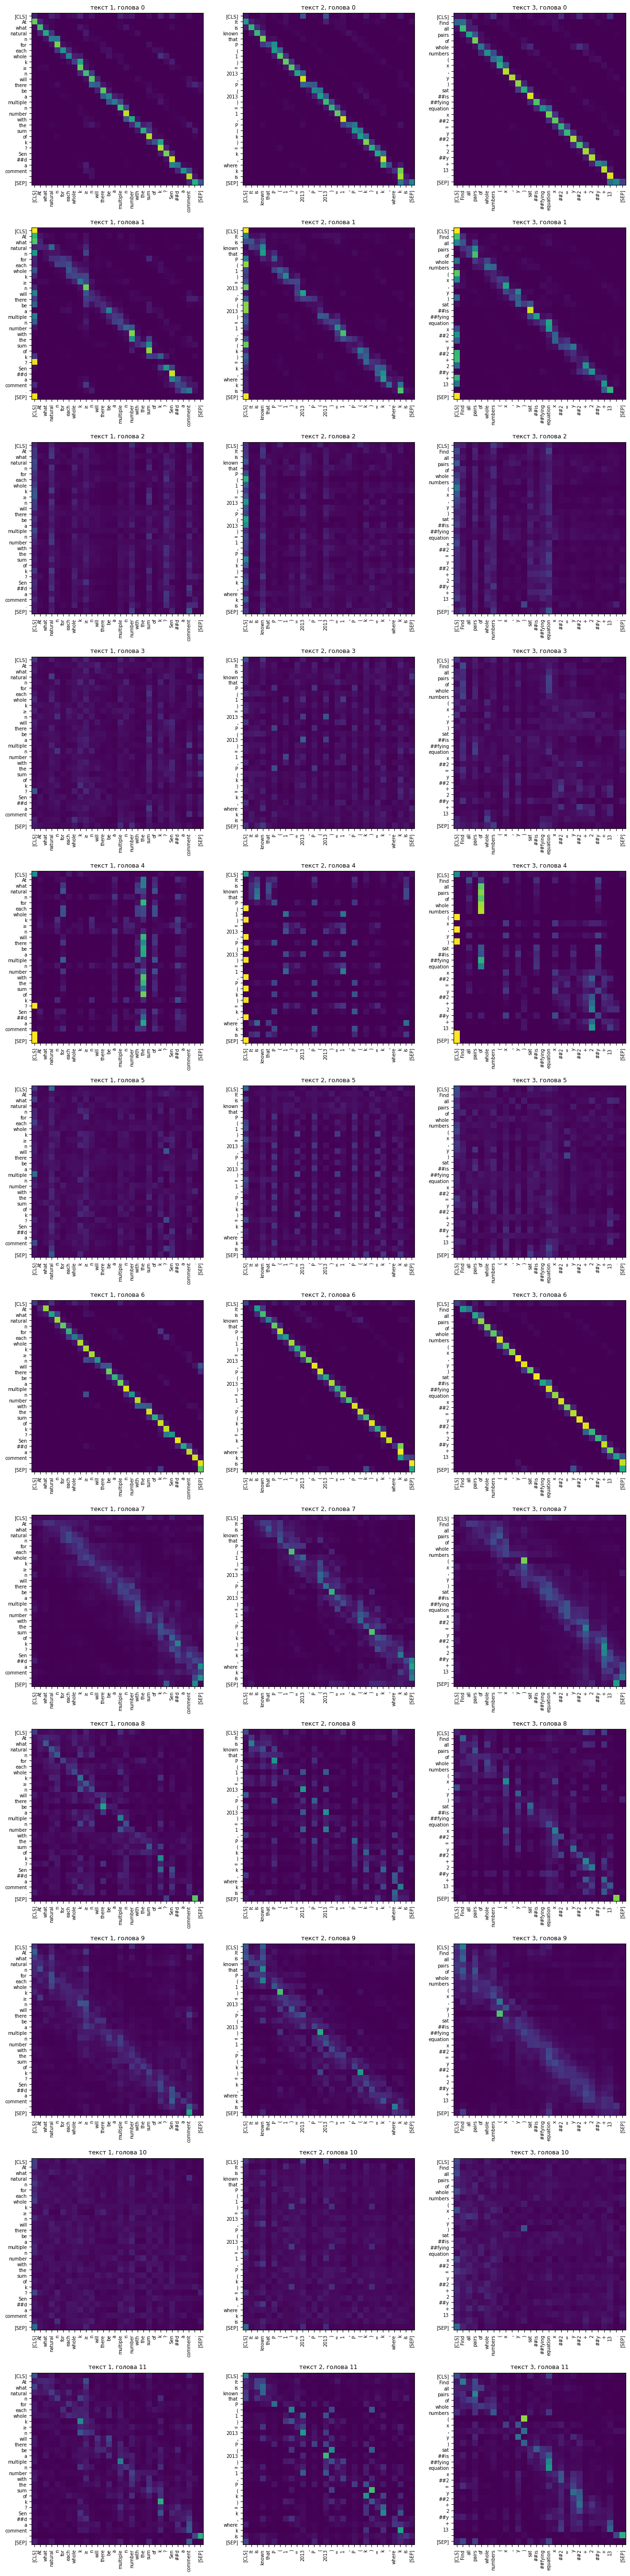

In [141]:
draw_first_layer_attention_maps(np.arange(rubert_frozen.backbone.config.num_attention_heads), 
                                texts, rubert_frozen, rubert_tokenizer)

Здесь можно заметить ярковыраженную диагональную зависимость на 0, 1 и 6 головах. то есть 0 голова смотрит на предыдущий токен, а 6 на следующий. после 6 головы прослеживается динамика диагональной зависимости, но она не такая яркая, как в перечисленных выше головах, а значит внимание примерно распределено между соседними токенами. наиболее распределенное между токенами внимание можно заметить на 2, 3 и 5 головах

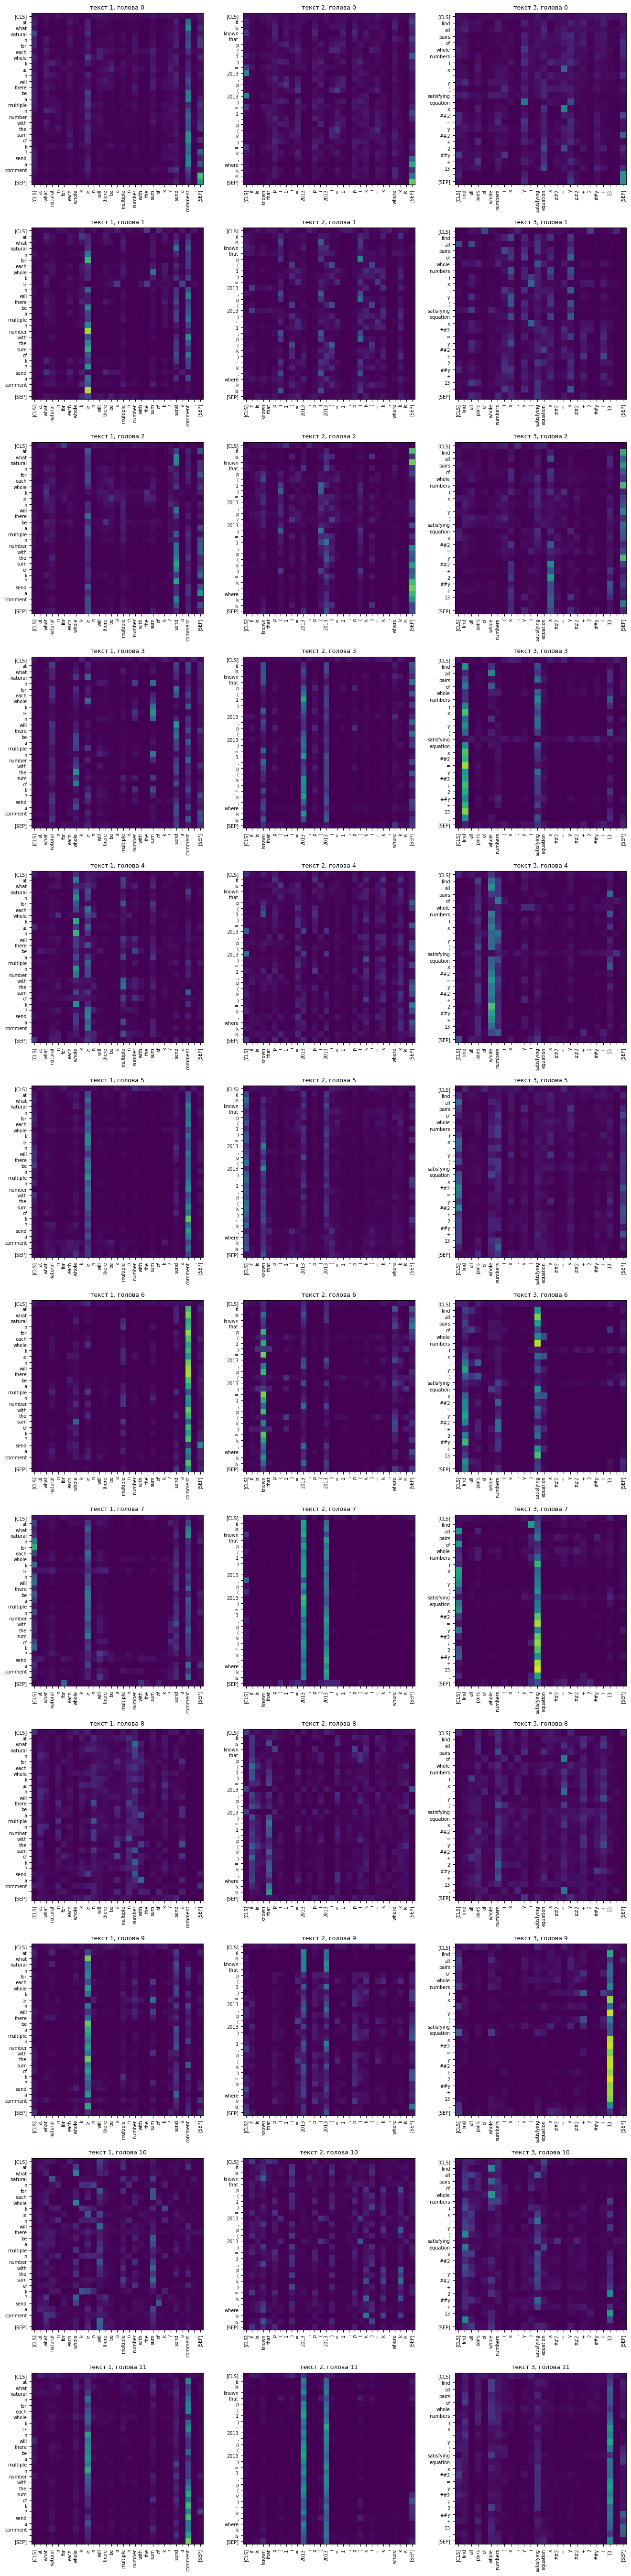

In [143]:
draw_first_layer_attention_maps(np.arange(mathbert_frozen.backbone.config.num_attention_heads), 
                                texts, mathbert_frozen, mathbert_tokenizer)

Здесь вообще нет диагональной зависимости. Внимание либо равномерно распределено между токенами (например, голова 8), либо (что чаще для этой модели) имеет столбчатый вид. это означает, что модель смотрит на какие то важные для интерпретации текста токены (например, find/comment/13/>=)

### Задание 8 (1 балл)

Сделайте то же самое для дообученных моделей. Изменились ли карты внимания и связи, которые они улавливают? Почему?

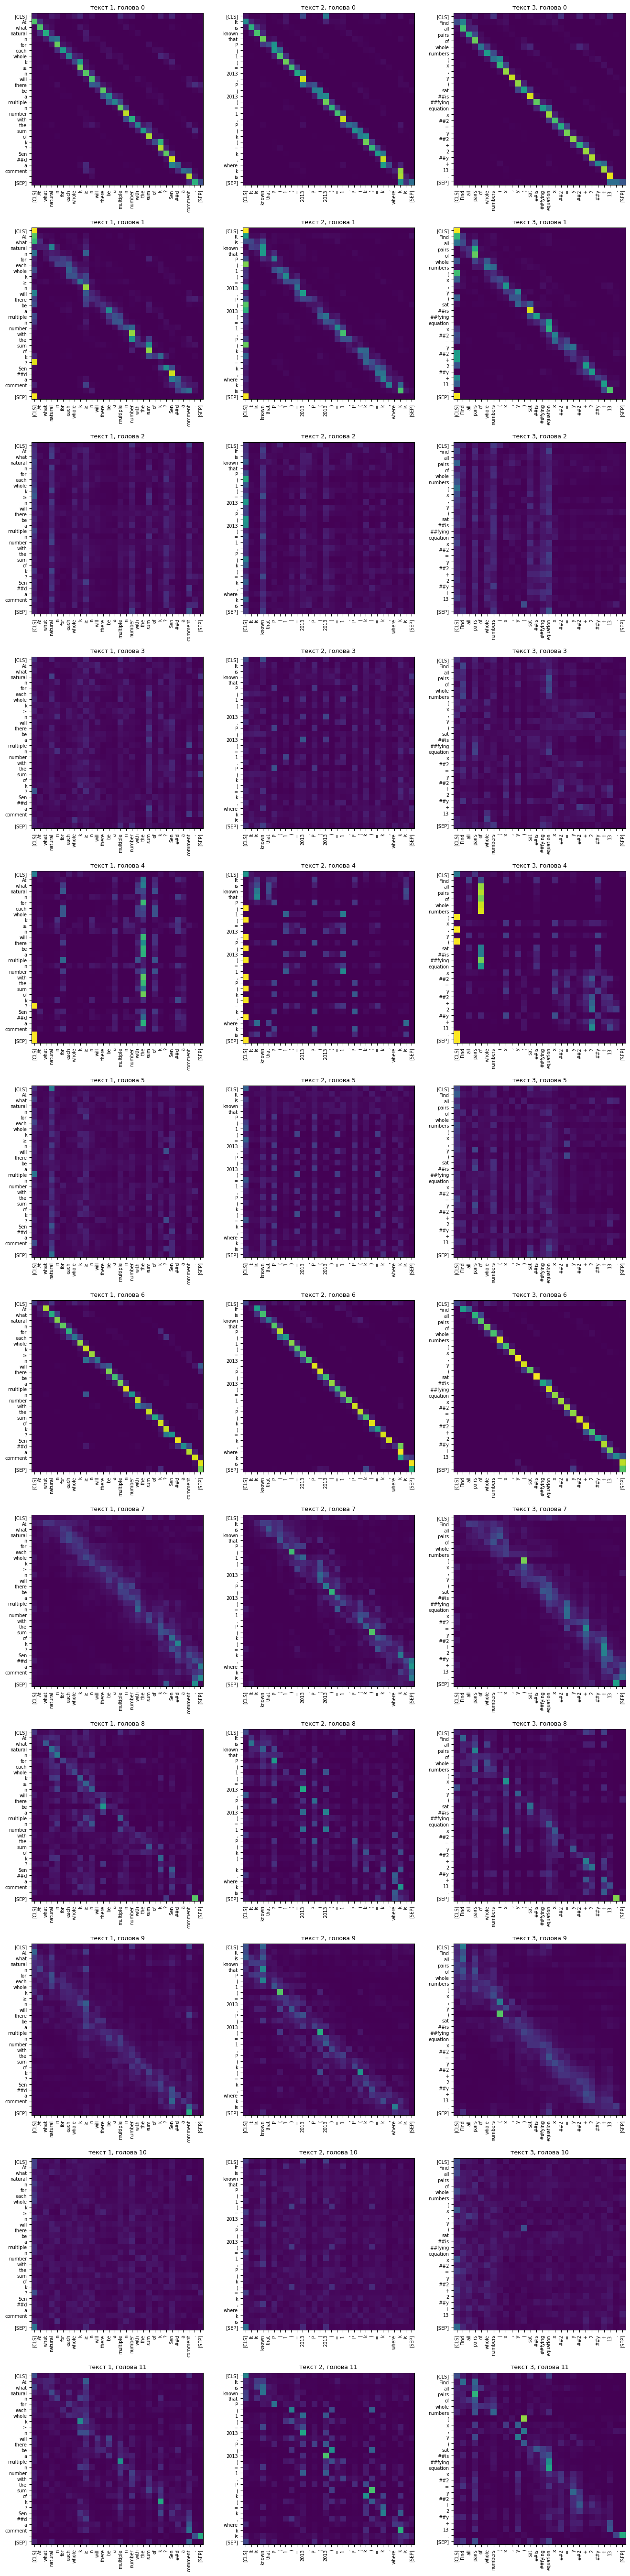

In [144]:
draw_first_layer_attention_maps(np.arange(rubert_full.backbone.config.num_attention_heads), 
                                texts, rubert_full, rubert_tokenizer)

Здесь для rubert картина в целом сохраняется. 0, 1, 6 - диагональные зависимости. после 6 - внимание распределено меджу соседними токенами

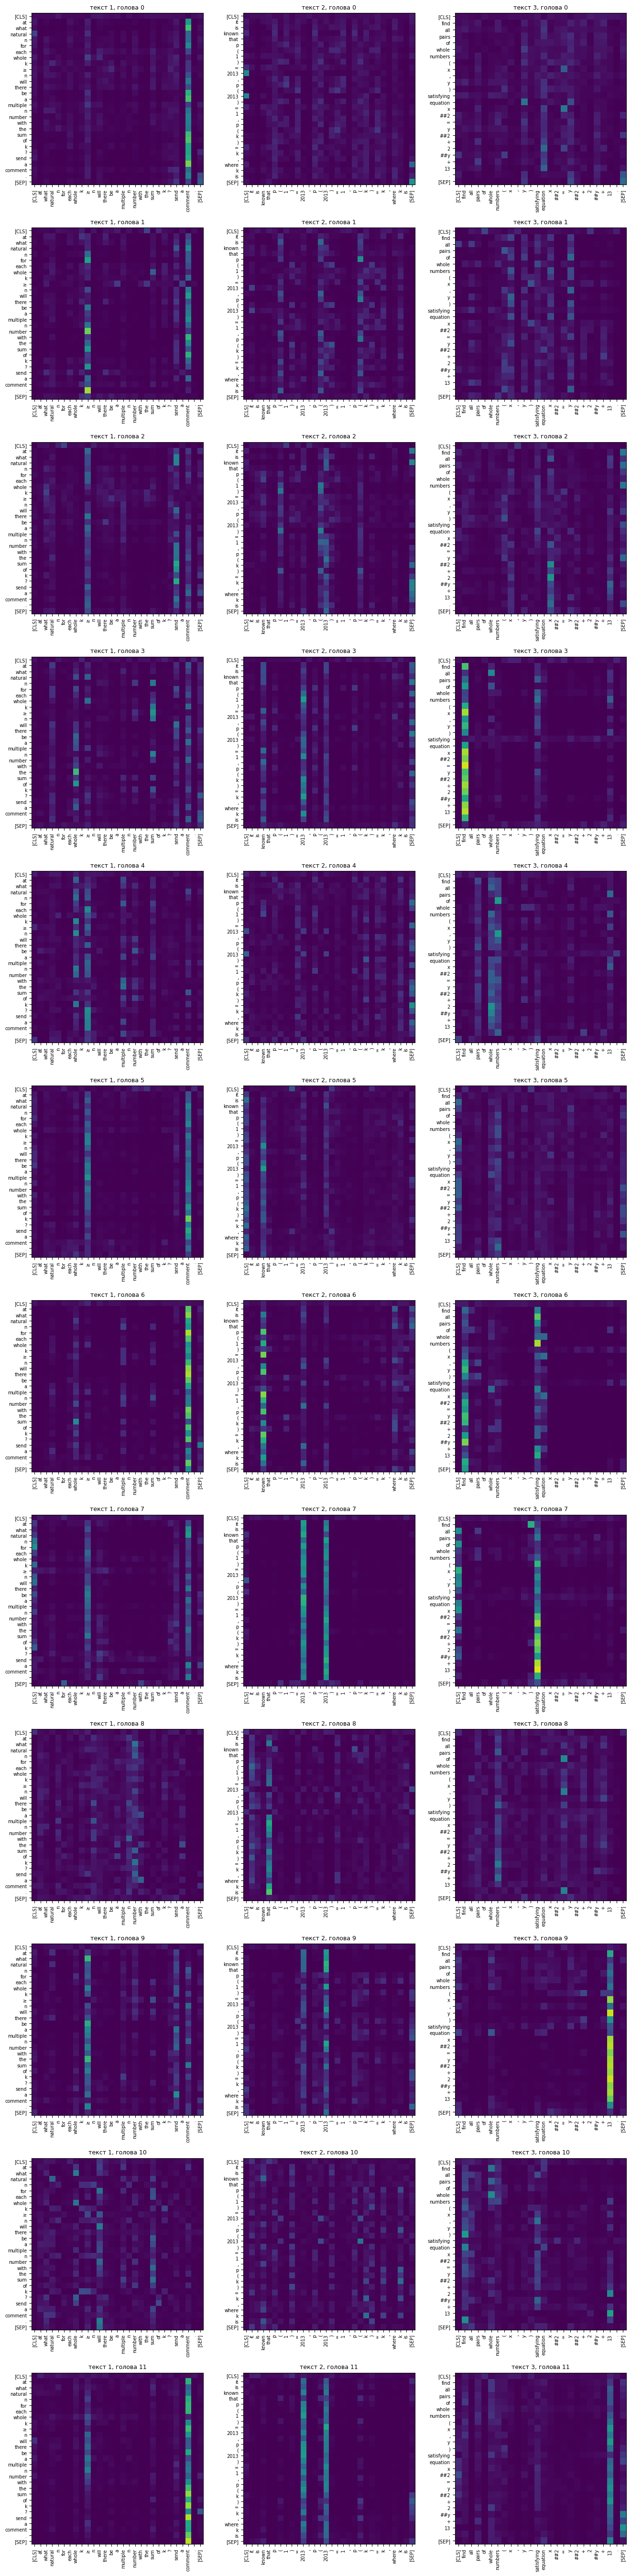

In [145]:
draw_first_layer_attention_maps(np.arange(mathbert_full.backbone.config.num_attention_heads), 
                                texts, mathbert_full, mathbert_tokenizer)

Здесь тоже не замечаю кардинального отличия карт внимания. все те же стобцы, которые показывают важные для модели слова. только теперь в этом можно точно убедиться, тк backbone тоже дообучался. диагональных зависимостей как не было, так и нет

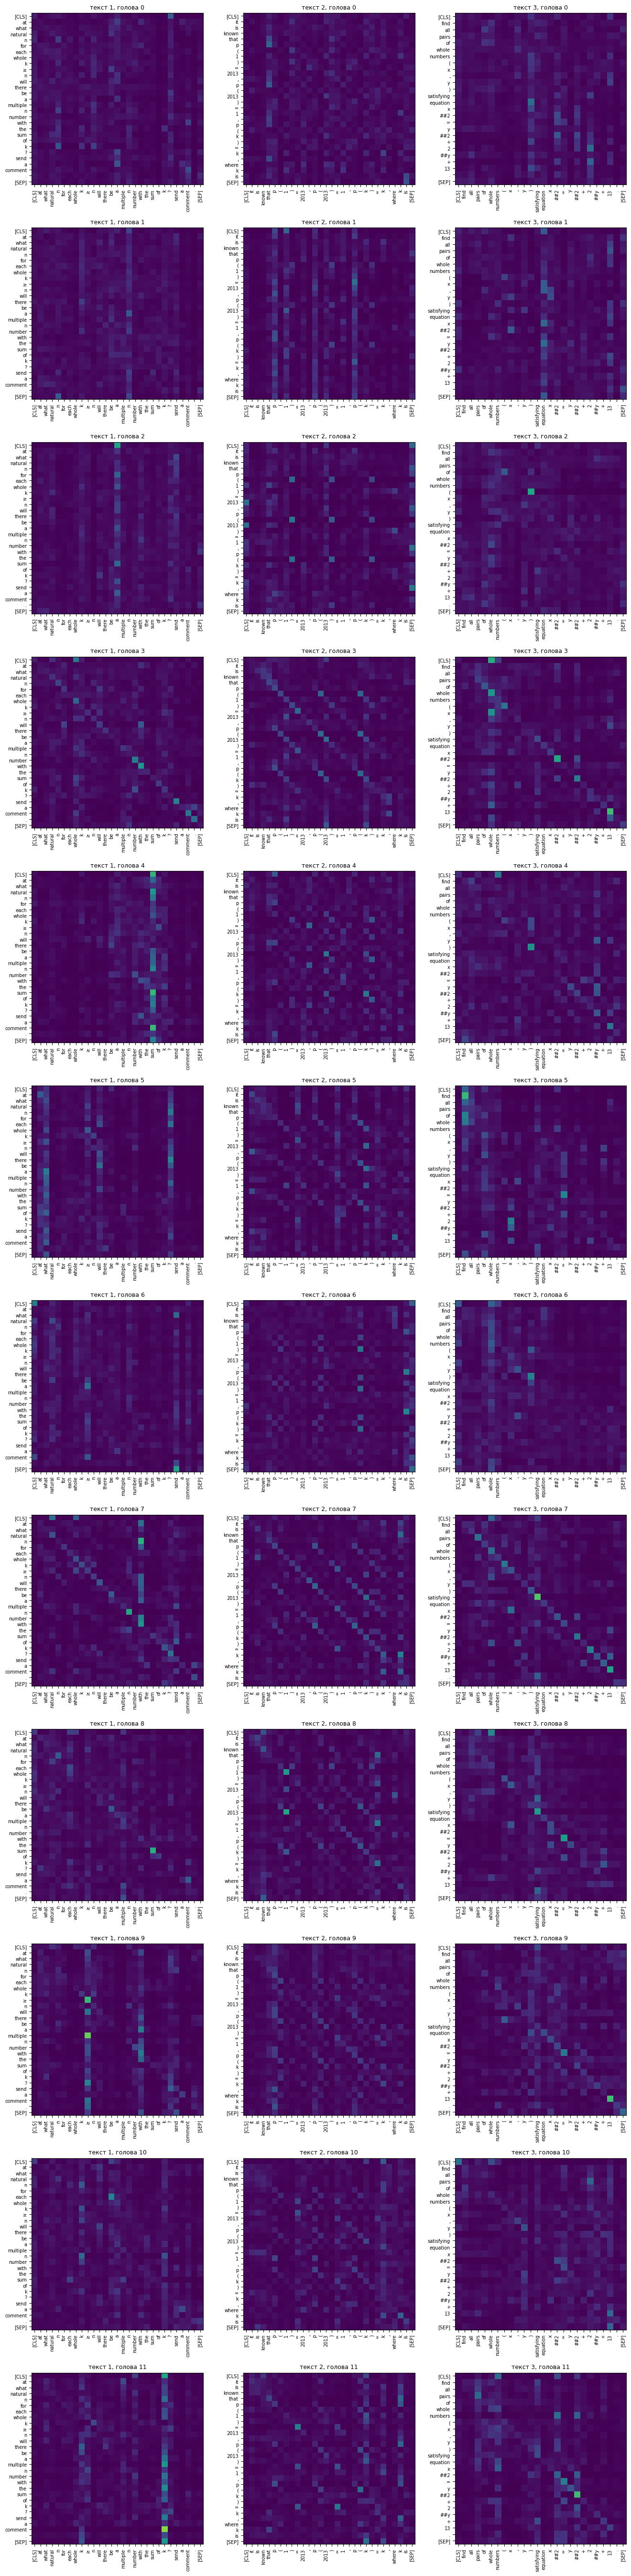

In [150]:
draw_first_layer_attention_maps(np.arange(mathbert_full.backbone.config.num_attention_heads), 
                                texts, mathbert_full, mathbert_tokenizer, layer=-1)

### Вывод

В целом, ожидаемое поведение. При дообучении начальные слои внимания особо не меняются, тк они выделяют общие низкоуровневые паттерны. Как можно заматить для примера вывода карты внимания последнего слоя, картина уже меняется. появились диагональные зависимости, которые указывают на то, что модель смотрит на соседние токены. Также ушло большее число столбцов, тк такая низкоуровневая информация, как важность слов, должна учитываться на ранних слоях модели.